# Contexto da desigualdade regional de renda no Brasil, 2002–2023

Calcula o crescimento da renda per capita nacional, a renda relativa das grandes regiões, as participações no PIB e na população e o índice de Theil entre os estados (seção 4.1 do TCC).

Os dados vêm do Ipeadata e devem estar na pasta `../dados_usados` (ver o README do repositório).

In [1]:
# ----------------------------------------------------------------------------
# 1. BIBLIOTECAS E PARÂMETROS
# ----------------------------------------------------------------------------
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy.stats import spearmanr

# As séries do Brasil e do deflator vêm em .xls; o pandas precisa do pacote xlrd
import importlib.util, subprocess, sys
if importlib.util.find_spec("xlrd") is None:
    print("Pacote xlrd não encontrado; instalando...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "xlrd>=2.0.1"])
    importlib.invalidate_caches()

PASTA_DADOS = os.path.join("..", "dados_usados")
ARQ = {
    "pibpc":    "PIBPCE_pib_estadual_per_capita_precos_2010_[17-08-2026].csv",
    "pib":      "PIBPMCE_pib_estadual_precos_correntes_[10-11-2026].csv",
    "pop":      "POP_PROJE_populacao_residente_projecao_IBGE_[10-11-2026].csv",
    "brasil":   "GAC_PIBCAPN_pib_per_capita_brasil_nominal_[04-11-2026].xls",
    "deflator": "SCN10_DIPIBG10_deflator_implicito_pib_[04-11-2026].xls",
}
ANO_INICIAL, ANO_FINAL, ANO_BASE = 2002, 2023, 2010
ANOS = list(range(ANO_INICIAL, ANO_FINAL + 1))
ANOS_TAB = [2002, 2012, 2023]
CORTES = [0.5, 0.75, 1.0, 1.5]                  # limites das faixas da cadeia de Markov

REGIOES = {  # grandes regiões do IBGE
    "Norte":        ["RO", "AC", "AM", "RR", "PA", "AP", "TO"],
    "Nordeste":     ["MA", "PI", "CE", "RN", "PB", "PE", "AL", "SE", "BA"],
    "Sudeste":      ["MG", "ES", "RJ", "SP"],
    "Sul":          ["PR", "SC", "RS"],
    "Centro-Oeste": ["MS", "MT", "GO", "DF"],
}
REGIAO_DE = {uf: r for r, ufs in REGIOES.items() for uf in ufs}
assert len(REGIAO_DE) == 27

PASTA_TAB = os.path.join("resultados", "tabelas")
PASTA_FIG = os.path.join("resultados", "figuras")
for p in [PASTA_TAB, PASTA_FIG]:
    os.makedirs(p, exist_ok=True)
pd.set_option("display.width", 200)

In [2]:
# ----------------------------------------------------------------------------
# 2. LEITURA E VALIDAÇÃO
# ----------------------------------------------------------------------------
def ler_csv_ipeadata(nome):
    d = pd.read_csv(os.path.join(PASTA_DADOS, nome), skiprows=1, encoding="utf-8-sig")
    d = d.loc[:, ~d.columns.str.startswith("Unnamed")]
    anos = [c for c in d.columns if c.isdigit()]
    t = d.set_index("Sigla")[anos].astype(float)
    t.columns = t.columns.astype(int)
    assert t.shape[0] == 27 and t.index.nunique() == 27, f"{nome}: não há 27 UF"
    return t, d.set_index("Sigla")["Estado"]

def ler_serie_ipeadata(nome):
    x = pd.read_excel(os.path.join(PASTA_DADOS, nome), header=0)
    x.columns = ["ano", "valor"]
    x = x[x["ano"].astype(str).str.fullmatch(r"\d{4}")]
    return pd.Series(x["valor"].astype(float).values, index=x["ano"].astype(int).values)

pibpc, nomes = ler_csv_ipeadata(ARQ["pibpc"])
pib, _ = ler_csv_ipeadata(ARQ["pib"])
pop, _ = ler_csv_ipeadata(ARQ["pop"])
brasil_nominal = ler_serie_ipeadata(ARQ["brasil"])
deflator_var = ler_serie_ipeadata(ARQ["deflator"])

for nome, t in [("PIBPCE", pibpc), ("PIBPMCE", pib), ("POP_PROJE", pop)]:
    assert set(ANOS) <= set(t.columns), f"{nome}: faltam anos"
    assert t[ANOS].isna().sum().sum() == 0, f"{nome}: há valores ausentes"
assert set(REGIAO_DE) == set(pibpc.index)
print("Leitura validada: 27 UF, 2002-2023, sem valores ausentes.")

Leitura validada: 27 UF, 2002-2023, sem valores ausentes.


In [3]:
# ----------------------------------------------------------------------------
# 3. PIB PER CAPITA DO BRASIL A PREÇOS DE 2010 (mesma construção do notebook do Quah)
#    e fases do crescimento nacional
# ----------------------------------------------------------------------------
indice = {ANO_BASE: 1.0}
for t in range(ANO_BASE + 1, ANO_FINAL + 1):
    indice[t] = indice[t - 1] * (1 + deflator_var[t] / 100)
for t in range(ANO_BASE, ANO_INICIAL, -1):
    indice[t - 1] = indice[t] / (1 + deflator_var[t] / 100)
indice = pd.Series(indice).sort_index().loc[ANO_INICIAL:ANO_FINAL]
brasil_real = brasil_nominal.loc[ANO_INICIAL:ANO_FINAL] / indice          # R$ mil de 2010

cresc = 100 * np.log(brasil_real).diff()                                  # % a.a. (log)
fases = [("2003-2013", 2003, 2013), ("2014-2016", 2014, 2016), ("2017-2019", 2017, 2019),
         ("2020", 2020, 2020), ("2021-2023", 2021, 2023), ("2003-2023 (período todo)", 2003, 2023)]
tab_fases = pd.DataFrame([{"Fase": f, "Crescimento médio anual (% a.a.)": cresc.loc[a:b].mean(),
                           "Anos": b - a + 1} for f, a, b in fases])
print("PIB per capita do Brasil, R$ mil de 2010:")
print(brasil_real.round(2).to_string())
print("\nCrescimento anual (%):")
print(cresc.dropna().round(1).to_string())
print("\nFases:")
print(tab_fases.round(2).to_string(index=False))
print(f"\nVariação acumulada 2002-2023: {100 * (brasil_real[ANO_FINAL] / brasil_real[ANO_INICIAL] - 1):.1f}%")

pd.DataFrame({"pib_pc_brasil_2010": brasil_real, "crescimento_pct": cresc}).round(4).to_csv(
    os.path.join(PASTA_TAB, "contexto_crescimento_nacional.csv"), encoding="utf-8-sig")
tab_fases.round(3).to_csv(os.path.join(PASTA_TAB, "contexto_fases_crescimento.csv"), index=False, encoding="utf-8-sig")

PIB per capita do Brasil, R$ mil de 2010:
2002    16.19
2003    16.19
2004    16.95
2005    17.32
2006    17.83
2007    18.71
2008    19.44
2009    19.18
2010    20.37
2011    20.94
2012    21.11
2013    21.52
2014    21.44
2015    20.52
2016    19.72
2017    19.87
2018    20.15
2019    20.35
2020    19.68
2021    20.64
2022    21.34
2023    21.93

Crescimento anual (%):
2003    0.0
2004    4.6
2005    2.2
2006    2.9
2007    4.8
2008    3.8
2009   -1.4
2010    6.0
2011    2.7
2012    0.8
2013    2.0
2014   -0.4
2015   -4.4
2016   -4.0
2017    0.8
2018    1.4
2019    1.0
2020   -3.4
2021    4.8
2022    3.3
2023    2.7

Fases:
                    Fase  Crescimento médio anual (% a.a.)  Anos
               2003-2013                              2.59    11
               2014-2016                             -2.93     3
               2017-2019                              1.06     3
                    2020                             -3.37     1
               2021-2023                 

In [4]:
# ----------------------------------------------------------------------------
# 4. RENDA RELATIVA DAS REGIÕES E PARTICIPAÇÕES (Figura 1 e Tabela 1)
# ----------------------------------------------------------------------------
pib_br, pop_br = pib[ANOS].sum(), pop[ANOS].sum()
rel_reg = pd.DataFrame({r: (pib.loc[u, ANOS].sum() / pop.loc[u, ANOS].sum()) / (pib_br / pop_br)
                        for r, u in REGIOES.items()})
print("Renda relativa das regiões (Brasil = 1):")
print(rel_reg.loc[ANOS_TAB].round(3).to_string())

linhas = []
for r, u in REGIOES.items():
    l = {"Região": r}
    for a in [ANO_INICIAL, ANO_FINAL]:
        l[f"PIB {a} (%)"] = 100 * pib.loc[u, a].sum() / pib_br[a]
        l[f"População {a} (%)"] = 100 * pop.loc[u, a].sum() / pop_br[a]
        l[f"Renda relativa {a}"] = rel_reg.loc[a, r]
    linhas.append(l)
tab1 = pd.DataFrame(linhas)
tot = {"Região": "Brasil"}
for a in [ANO_INICIAL, ANO_FINAL]:
    tot[f"PIB {a} (%)"] = tab1[f"PIB {a} (%)"].sum(); tot[f"População {a} (%)"] = tab1[f"População {a} (%)"].sum()
    tot[f"Renda relativa {a}"] = 1.0
tab1 = pd.concat([tab1, pd.DataFrame([tot])], ignore_index=True)
print("\nTabela 1:")
print(tab1.round(2).to_string(index=False))

rel_reg.round(4).to_csv(os.path.join(PASTA_TAB, "contexto_renda_relativa_regioes.csv"), encoding="utf-8-sig")
tab1.round(3).to_csv(os.path.join(PASTA_TAB, "contexto_tabela1_participacoes.csv"), index=False, encoding="utf-8-sig")

Renda relativa das regiões (Brasil = 1):
      Norte  Nordeste  Sudeste    Sul  Centro-Oeste
2002  0.604     0.469    1.343  1.117         1.222
2012  0.641     0.494    1.321  1.109         1.235
2023  0.664     0.514    1.269  1.148         1.328

Tabela 1:
      Região  PIB 2002 (%)  População 2002 (%)  Renda relativa 2002  PIB 2023 (%)  População 2023 (%)  Renda relativa 2023
       Norte          4.70                7.77                 0.60          5.82                8.76                 0.66
    Nordeste         13.09               27.93                 0.47         13.83               26.91                 0.51
     Sudeste         57.38               42.72                 1.34         53.00               41.75                 1.27
         Sul         16.23               14.53                 1.12         16.76               14.60                 1.15
Centro-Oeste          8.61                7.05                 1.22         10.60                7.98                 1.33
  

In [5]:
# ----------------------------------------------------------------------------
# 5. ÍNDICE DE THEIL ENTRE OS ESTADOS E DECOMPOSIÇÃO (Figura 2) + razão máximo/mínimo
# ----------------------------------------------------------------------------
def theil(y, w):
    """Theil de Azzoni (1997): J = Σ n_e ln(ȳ / y_e), n_e = participação na população."""
    n = w / w.sum(); ybar = (n * y).sum()
    return (n * np.log(ybar / y)).sum()

linhas = []
for a in ANOS:
    y, w = pibpc[a], pop[a]
    n = w / w.sum(); ybar = (n * y).sum()
    J = theil(y, w)
    entre = sum(n[u].sum() * np.log(ybar / ((n[u] * y[u]).sum() / n[u].sum())) for u in REGIOES.values())
    dentro = sum(n[u].sum() * theil(y[u], w[u]) for u in REGIOES.values())
    assert abs(J - (entre + dentro)) < 1e-10, "A decomposição não fecha"
    sem_df = y.drop(index="DF")
    linhas.append({"Ano": a, "Theil": J, "Entre regiões": entre, "Dentro das regiões": dentro,
                   "Entre regiões (% do total)": 100 * entre / J,
                   "Maior/menor": y.max() / y.min(), "Maior": y.idxmax(), "Menor": y.idxmin(),
                   "Maior/menor sem DF": sem_df.max() / sem_df.min(), "Maior sem DF": sem_df.idxmax()})
tab_theil = pd.DataFrame(linhas).set_index("Ano")
print(tab_theil.round(3).to_string())
print(f"\nTheil: {tab_theil.loc[ANO_INICIAL, 'Theil']:.3f} -> {tab_theil.loc[ANO_FINAL, 'Theil']:.3f} "
      f"({100 * (tab_theil.loc[ANO_FINAL, 'Theil'] / tab_theil.loc[ANO_INICIAL, 'Theil'] - 1):.1f}%); "
      f"mínimo em {tab_theil['Theil'].idxmin()} ({tab_theil['Theil'].min():.3f})")
tab_theil.round(5).to_csv(os.path.join(PASTA_TAB, "contexto_theil_decomposicao.csv"), encoding="utf-8-sig")

      Theil  Entre regiões  Dentro das regiões  Entre regiões (% do total)  Maior/menor Maior Menor  Maior/menor sem DF Maior sem DF
Ano                                                                                                                                 
2002  0.130          0.096               0.034                      73.528       10.221    DF    PI               5.530           SP
2003  0.127          0.097               0.030                      76.632        9.275    DF    PI               5.309           SP
2004  0.122          0.095               0.027                      77.815        9.295    DF    PI               5.185           SP
2005  0.124          0.094               0.030                      76.098        9.112    DF    PI               5.157           SP
2006  0.120          0.091               0.028                      76.316        8.071    DF    PI               4.564           SP
2007  0.125          0.097               0.028                      7

In [6]:
# ----------------------------------------------------------------------------
# 6. RENDA RELATIVA DOS 27 ESTADOS, 2002 E 2023 (Figura 3) — a mesma da cadeia de Markov
# ----------------------------------------------------------------------------
x = pibpc[ANOS].div(brasil_real[ANOS], axis=1)
tab_uf = pd.DataFrame({"Estado": nomes, "Região": pd.Series(REGIAO_DE),
                       "2002": x[ANO_INICIAL], "2023": x[ANO_FINAL]})
tab_uf["Variação"] = tab_uf["2023"] - tab_uf["2002"]
faixa = lambda v: int(np.digitize(v, CORTES) + 1)
tab_uf["Faixa 2002"] = tab_uf["2002"].apply(faixa)
tab_uf["Faixa 2023"] = tab_uf["2023"].apply(faixa)
tab_uf = tab_uf.sort_values("2023", ascending=False)
rho = spearmanr(x[ANO_INICIAL], x[ANO_FINAL])[0]
print(tab_uf.round(3).to_string())
print(f"\nCorrelação de postos (Spearman) 2002 x 2023: {rho:.3f}")
print("Maiores altas:", tab_uf["Variação"].nlargest(5).round(3).to_dict())
print("Maiores quedas:", tab_uf["Variação"].nsmallest(5).round(3).to_dict())
print("Mudaram de faixa entre 2002 e 2023:",
      tab_uf.loc[tab_uf["Faixa 2002"] != tab_uf["Faixa 2023"], ["Faixa 2002", "Faixa 2023"]].to_dict("index"))
tab_uf.round(4).to_csv(os.path.join(PASTA_TAB, "contexto_renda_relativa_estados.csv"), encoding="utf-8-sig")

                 Estado        Região   2002   2023  Variação  Faixa 2002  Faixa 2023
DF     Distrito Federal  Centro-Oeste  2.948  2.406    -0.542           5           5
SP            São Paulo       Sudeste  1.595  1.442    -0.153           5           4
MT          Mato Grosso  Centro-Oeste  0.865  1.370     0.505           3           4
RJ       Rio de Janeiro       Sudeste  1.469  1.362    -0.107           4           4
SC       Santa Catarina           Sul  1.157  1.237     0.080           4           4
MS   Mato Grosso do Sul  Centro-Oeste  0.901  1.237     0.335           3           4
RS    Rio Grande do Sul           Sul  1.115  1.113    -0.001           4           4
PR               Paraná           Sul  1.057  1.087     0.030           4           4
ES       Espírito Santo       Sudeste  0.991  1.014     0.023           3           4
RO             Rondônia         Norte  0.612  0.898     0.286           2           3
GO                Goiás  Centro-Oeste  0.870  0.881   

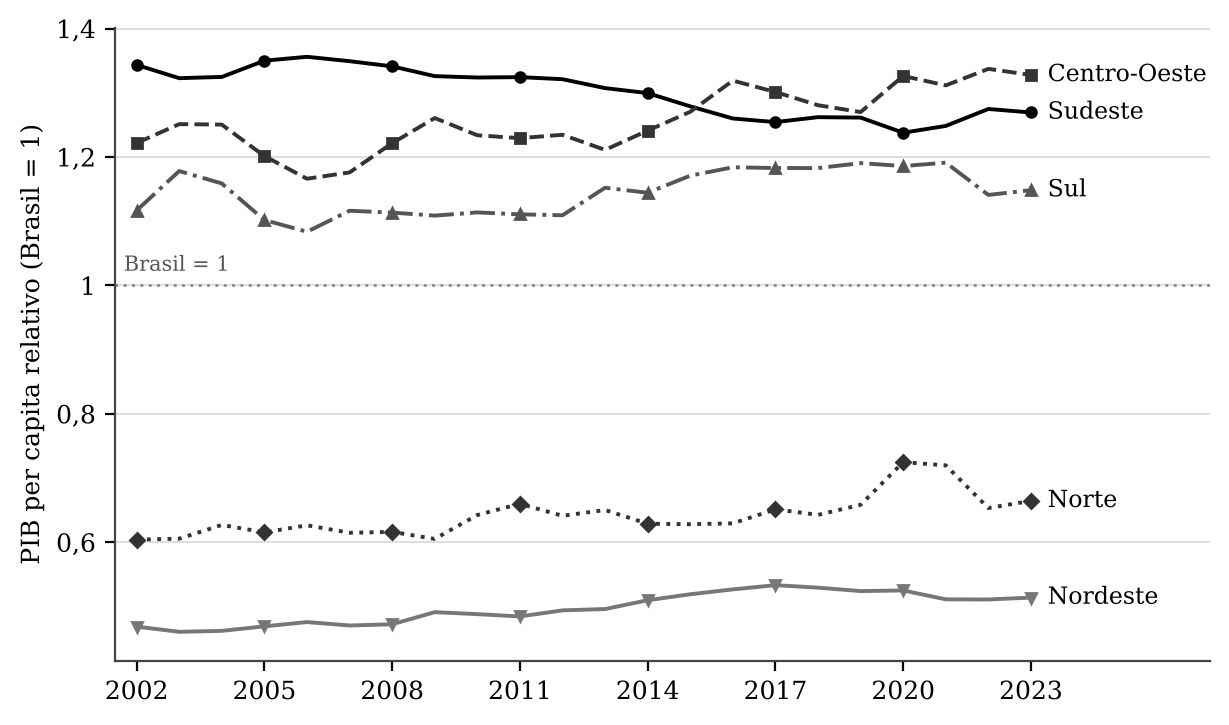

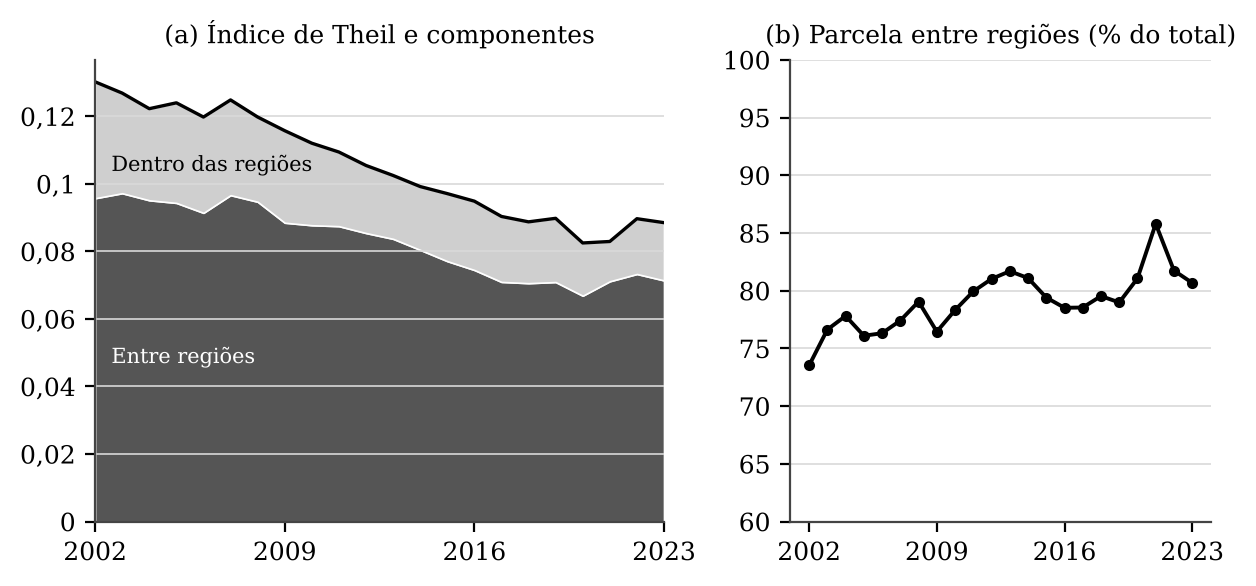

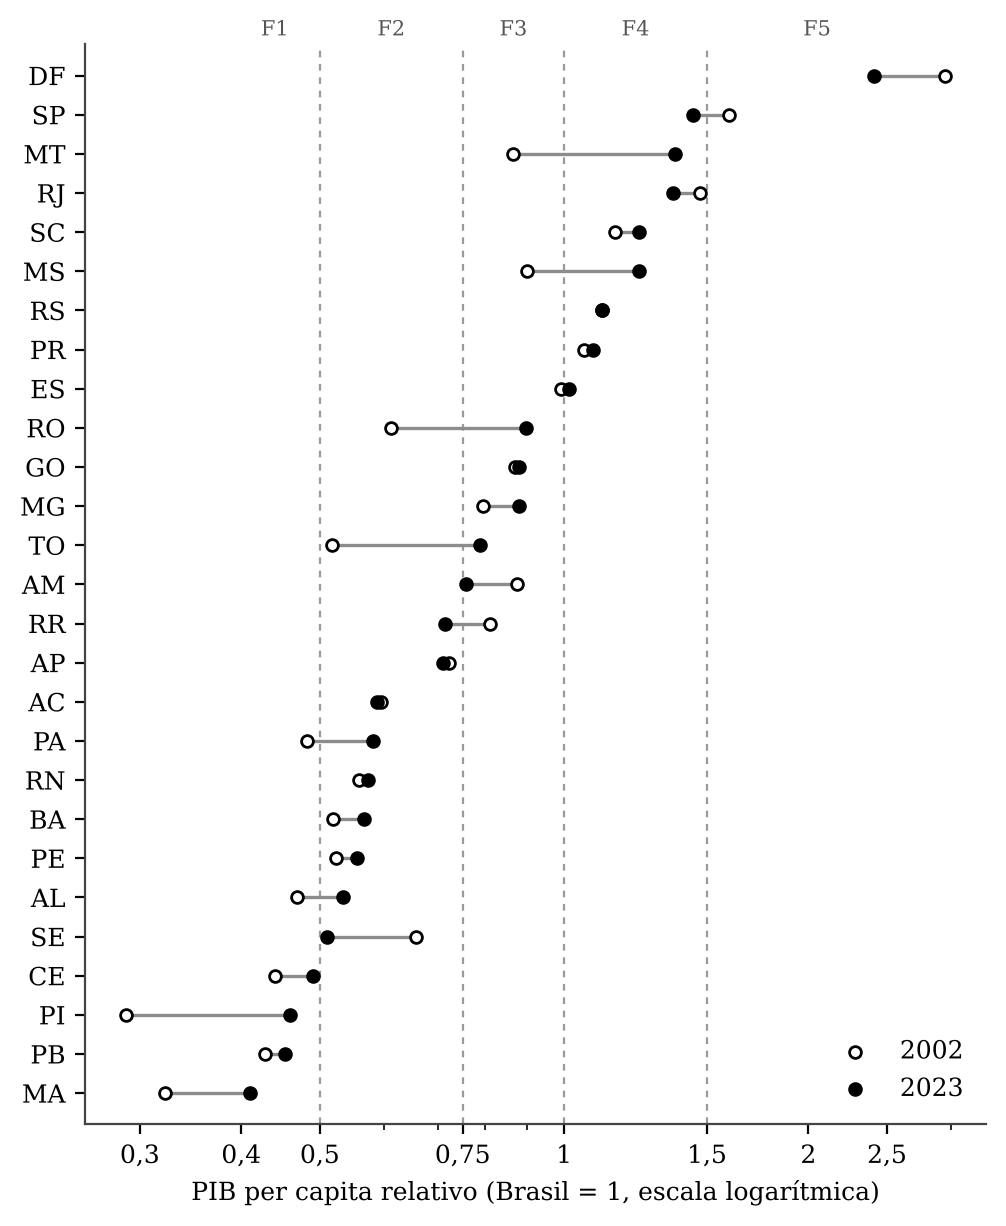

Tabelas: ['contexto_crescimento_nacional.csv', 'contexto_fases_crescimento.csv', 'contexto_renda_relativa_estados.csv', 'contexto_renda_relativa_regioes.csv', 'contexto_tabela1_participacoes.csv', 'contexto_theil_decomposicao.csv']
Figuras: ['contexto_fig1_renda_relativa_regioes.png', 'contexto_fig2_theil.png', 'contexto_fig3_renda_relativa_estados.png']


In [7]:
# ----------------------------------------------------------------------------
# 7. FIGURAS (preto e cinza, para impressão; vírgula decimal; título e fonte no texto)
#    Tamanhos já no tamanho de impressão (largura do texto = 16 cm = 6,3 pol.), para a fonte sair com 9 pt
# ----------------------------------------------------------------------------
plt.rcParams.update({"font.family": "serif", "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.edgecolor": "#444444"})
VIRG = FuncFormatter(lambda v, pos: f"{v:g}".replace(".", ","))
GRADE = dict(color="#d9d9d9", lw=0.6)

# Figura 1 — renda relativa das regiões, 2002-2023
estilo = {"Sudeste": ("-", "o"), "Centro-Oeste": ("--", "s"), "Sul": ("-.", "^"),
          "Norte": (":", "D"), "Nordeste": ("-", "v")}
cinza = {"Sudeste": "#000000", "Centro-Oeste": "#333333", "Sul": "#555555", "Norte": "#333333", "Nordeste": "#777777"}
fig, ax = plt.subplots(figsize=(6.3, 3.7))
ax.axhline(1, color="#888888", lw=1, ls=(0, (1, 2)))
ax.text(ANO_INICIAL - 0.3, 1.015, "Brasil = 1", fontsize=7.5, color="#555555", va="bottom")
for r in REGIOES:
    ls, mk = estilo[r]
    ax.plot(ANOS, rel_reg[r], ls=ls, marker=mk, ms=3.5, lw=1.4, color=cinza[r], markevery=3)
    ax.annotate(r, (ANO_FINAL, rel_reg.loc[ANO_FINAL, r]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=8.5)
ax.set_xlim(ANO_INICIAL - 0.5, ANO_FINAL + 4.2)
ax.set_xticks(range(ANO_INICIAL, ANO_FINAL + 1, 3))
ax.set_ylabel("PIB per capita relativo (Brasil = 1)")
ax.yaxis.set_major_formatter(VIRG); ax.grid(axis="y", **GRADE)
plt.tight_layout()
plt.savefig(os.path.join(PASTA_FIG, "contexto_fig1_renda_relativa_regioes.png"), dpi=300, bbox_inches="tight")
plt.show()

# Figura 2 — Theil ano a ano: (a) decomposição; (b) parcela entre regiões
fig, axs = plt.subplots(1, 2, figsize=(6.3, 3.0), gridspec_kw={"width_ratios": [1.35, 1]})
ax = axs[0]
ax.stackplot(ANOS, tab_theil["Entre regiões"], tab_theil["Dentro das regiões"],
             colors=["#555555", "#cfcfcf"], edgecolor="white", lw=0.6)
ax.plot(ANOS, tab_theil["Theil"], color="black", lw=1.2)
ax.text(2002.6, tab_theil.loc[2003, "Entre regiões"] / 2, "Entre regiões", color="white", fontsize=7.5, va="center")
ax.text(2002.6, 0.1055, "Dentro das regiões", color="black", fontsize=7.5, va="center")   # dentro da faixa clara
ax.set_title("(a) Índice de Theil e componentes", fontsize=9)
ax.set_xticks(range(ANO_INICIAL, ANO_FINAL + 1, 7)); ax.set_xlim(ANO_INICIAL, ANO_FINAL)
ax.set_ylim(0, None); ax.yaxis.set_major_formatter(VIRG); ax.grid(axis="y", **GRADE)
ax = axs[1]
ax.plot(ANOS, tab_theil["Entre regiões (% do total)"], color="black", lw=1.4, marker="o", ms=3)
ax.set_title("(b) Parcela entre regiões (% do total)", fontsize=9)
ax.set_xticks(range(ANO_INICIAL, ANO_FINAL + 1, 7)); ax.set_ylim(60, 100)
ax.yaxis.set_major_formatter(VIRG); ax.grid(axis="y", **GRADE)
plt.tight_layout()
plt.savefig(os.path.join(PASTA_FIG, "contexto_fig2_theil.png"), dpi=300, bbox_inches="tight")
plt.show()

# Figura 3 — renda relativa dos 27 estados, 2002 e 2023 (halteres)
t = tab_uf.sort_values("2023")
fig, ax = plt.subplots(figsize=(5.1, 6.2))
for c in CORTES:
    ax.axvline(c, color="#9a9a9a", lw=0.8, ls=(0, (3, 3)), zorder=0)
ypos = np.arange(len(t))
ax.hlines(ypos, t["2002"], t["2023"], color="#8c8c8c", lw=1.2, zorder=1)
ax.scatter(t["2002"], ypos, s=18, facecolor="white", edgecolor="black", lw=1, zorder=2, label="2002")
ax.scatter(t["2023"], ypos, s=18, color="black", zorder=3, label="2023")
ax.set_yticks(ypos); ax.set_yticklabels(t.index)
ax.set_xscale("log")
ax.set_xticks([0.3, 0.4, 0.5, 0.75, 1, 1.5, 2, 2.5]); ax.xaxis.set_major_formatter(VIRG)
ax.xaxis.set_minor_formatter(FuncFormatter(lambda v, p: ""))
ax.set_xlabel("PIB per capita relativo (Brasil = 1, escala logarítmica)")
ax.set_ylim(-0.8, len(t) - 0.2)
for k, (a, b) in enumerate(zip([0.35] + CORTES, CORTES + [3.0]), start=1):
    ax.text(np.sqrt(a * b) if k not in (1, 5) else (0.44 if k == 1 else 2.05), len(t) - 0.1, f"F{k}",
            ha="center", va="bottom", fontsize=7.5, color="#555555")
ax.legend(loc="lower right", frameon=False)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.savefig(os.path.join(PASTA_FIG, "contexto_fig3_renda_relativa_estados.png"), dpi=300, bbox_inches="tight")
plt.show()

print("Tabelas:", sorted(os.listdir(PASTA_TAB)))
print("Figuras:", sorted(os.listdir(PASTA_FIG)))